In [1]:
import os, glob, pickle
import numpy as np
import matplotlib.pyplot as plt

# ---- 路径与配置 ----
HERE = os.path.abspath("")                       # 笔记本所在目录（冻结K4_探索K4/）
DATA_DIR = os.path.join(HERE, "data")
GRAPH_DIR = os.path.join(HERE, "graph")
os.makedirs(GRAPH_DIR, exist_ok=True)

# 默认自动选 data/ 下最新一份训练 history pkl；也可直接写成具体路径
HISTORY_FILE = './data/26-10-23-06-16_history_K4_frozen4_deflation_MatrixFree_Pure.pkl'

# 诊断量归一化常数（与训练脚本一致）
N_CHAINS, N_SAMPLES_PER_CHAIN = 16, 200
AUX_M = 1024

In [2]:
with open(HISTORY_FILE, "rb") as f:
    data = pickle.load(f)

steps_arr = np.asarray(data["steps"], dtype=float)
lam_arr = np.asarray(data["lam"], dtype=float)
loss_arr = np.asarray(data["loss"], dtype=float)
diag = {k: np.asarray([d.get(k, np.nan) for d in data["diag"]], dtype=float)
        for k in data["diag"][0]}

K = lam_arr.shape[1]                 # active 列数（本实验 K=4）
N_ITER = len(steps_arr)
elapsed = float(data.get("elapsed_s", np.nan))
seed = data.get("seed", None)

# 参照基准 = 收尾 matrix-free 提取值（MC Gram 广义本征，无 FCI）
if data.get("lam_extract") is not None:
    ref_targets = np.sort(np.asarray(data["lam_extract"], dtype=float).real)[:K]
    ref_label = "extracted (MC Gram)"
else:
    ok_rows = np.isfinite(lam_arr).all(axis=1)
    ref_targets = lam_arr[ok_rows][-1] if ok_rows.any() else np.full(K, np.nan)
    ref_label = "last valid lambda_hat"

print(f"步数={N_ITER} | K={K} | seed={seed} | 耗时={elapsed:.1f}s")
print("收尾提取 λ =", np.round(ref_targets, 8), f"  ({ref_label})")

ok_rows = np.isfinite(lam_arr).all(axis=1)
if ok_rows.any():
    last_lam = lam_arr[ok_rows][-1]
    dev_mha = 1000.0 * np.max(np.abs(last_lam - ref_targets))
    print("末步 λ̂     =", np.round(last_lam, 8), f" | 与提取最大偏差 = {dev_mha:.4f} mHa")
    if dev_mha > 50.0:
        print("⚠ 偏差 > 50 mHa：该 pkl 的 lam 很可能来自旧监控量 eig(sym⟨E_L⟩)，"
              "请换用修复后的训练 pkl。")

步数=500 | K=4 | seed=11 | 耗时=431.5s
收尾提取 λ = [-0.02804312 -0.01450629 -0.0051726   0.02397392]   (extracted (MC Gram))
末步 λ̂     = [-0.02804421 -0.01450399 -0.0051714   0.02397164]  | 与提取最大偏差 = 0.0023 mHa


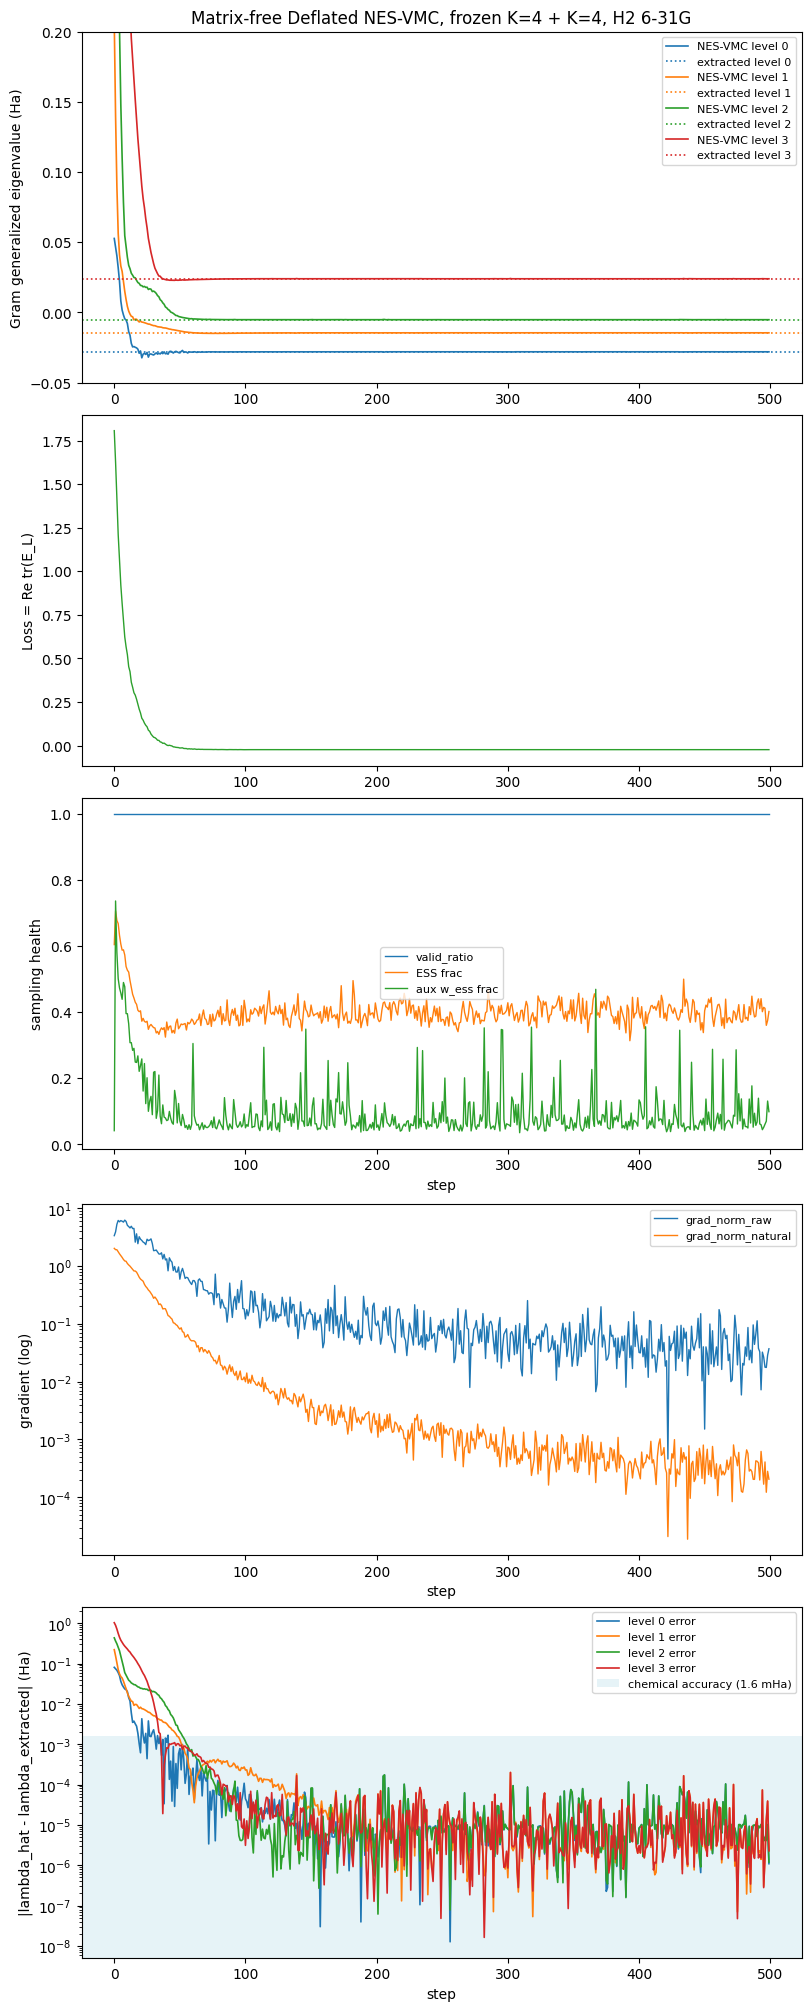

In [11]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"][:K]
fig, axs = plt.subplots(5, 1, figsize=(8, 20), constrained_layout=True)

# ---- 子图 1：Gram 广义本征 λ̂ + 收尾提取基准虚线 ----
for k in range(K):
    axs[0].plot(steps_arr, lam_arr[:, k], lw=1.2, color=colors[k],
                label=f"NES-VMC level {k}")
    axs[0].axhline(ref_targets[k], lw=1.2, ls=":", color=colors[k],
                   label=f"extracted level {k}")
axs[0].set_ylabel("Gram generalized eigenvalue (Ha)")
axs[0].set_title(
    f"Matrix-free Deflated NES-VMC, frozen K=4 + K={K}, H2 6-31G"
)
axs[0].set_ylim(-0.05,0.2)
axs[0].xaxis.set_major_formatter("{x:.0f}")
axs[0].legend(fontsize=8)

# ---- 子图 2：Loss（跳过步为 NaN，先掩码再画，防 NaN 断线）----
m = np.isfinite(loss_arr)
axs[1].plot(steps_arr[m], loss_arr[m], lw=1.0, color="#2ca02c")
axs[1].set_ylabel("Loss = Re tr(E_L)")
axs[1].xaxis.set_major_formatter("{x:.0f}")

# ---- 子图 3：采样健康度（归一为比例）----
for lbl, key, norm in [("valid_ratio", "valid_ratio", 1.0),
                       ("ESS frac", "ess", N_CHAINS * N_SAMPLES_PER_CHAIN),
                       ("aux w_ess frac", "w_ess", AUX_M)]:
    if key not in diag:
        continue
    v = diag[key] / norm
    mk = np.isfinite(v)
    axs[2].plot(steps_arr[mk], v[mk], lw=1.0, label=lbl)
axs[2].set_ylabel("sampling health")
axs[2].set_xlabel("step")
axs[2].xaxis.set_major_formatter("{x:.0f}")
axs[2].legend(fontsize=8)

# ---- 子图 4：梯度范数（log 轴）----
for key, lbl in [("grad_norm_raw", "grad_norm_raw"),
                 ("grad_norm_natural", "grad_norm_natural")]:
    if key not in diag:
        continue
    v = diag[key]
    mk = np.isfinite(v) & (v > 0)
    axs[3].semilogy(steps_arr[mk], v[mk], lw=1.0, label=lbl)
axs[3].set_ylabel("gradient (log)")
axs[3].set_xlabel("step")
axs[3].legend(fontsize=8)
axs[3].xaxis.set_major_formatter("{x:.0f}")

# ---- 子图 5：监控量收敛误差 |λ̂_k − λ_k(extracted)|（log 轴）----
for k in range(K):
    error_k = np.abs(lam_arr[:, k] - ref_targets[k])
    mk = np.isfinite(error_k) & (error_k > 0)   # 跳过步 NaN / 恰好命中点掩掉
    axs[4].semilogy(steps_arr[mk], error_k[mk], lw=1.2, color=colors[k],
                    label=f"level {k} error")
axs[4].axhspan(0, 0.0016, facecolor="lightblue", alpha=0.3, zorder=0,
               label="chemical accuracy (1.6 mHa)")
axs[4].set_ylabel("|lambda_hat - lambda_extracted| (Ha)")
axs[4].set_xlabel("step")
axs[4].set_yscale("log")
axs[4].xaxis.set_major_formatter("{x:.0f}")
axs[4].legend(fontsize=8)

plt.show()

In [4]:
out_png = os.path.join(
    GRAPH_DIR,
    os.path.basename(HISTORY_FILE).replace("history", "训练曲线").replace(".pkl", ".png"),
)
fig.savefig(out_png, dpi=150)
print("已保存图:", out_png)

已保存图: /Users/yangjianfei/mac_vscode/神经网络量子态/NES_VMC/experiments/H2分子/冻结K4_探索K4/graph/26-10-23-06-16_训练曲线_K4_frozen4_deflation_MatrixFree_Pure.png
